In [1]:
import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import random

from sklearn.preprocessing import StandardScaler

# Load prepared dataset
data = joblib.load("Dataset/cycle_time_data.joblib")

df = data["df"]
Xraw = data["Xraw"]
yraw = data["yraw"]
FEATURES = data["features"]
TRAIN_END = data["train_end"]

# PatchTST configuration
WINDOW = 10
PATCH_LEN = 5
STRIDE = 5

D_MODEL = 64
N_HEADS = 4
N_LAYERS = 2
DROPOUT = 0.1

EPOCHS = 15
BATCH = 32
LR = 0.001
SEED = 0

print("Dataset:", df.shape)
print("Input features:", Xraw.shape)
print("Target:", yraw.shape)
print("Features:", FEATURES)

print("\nPatchTST configuration:")
print("Window:", WINDOW)
print("Patch length:", PATCH_LEN)
print("Stride:", STRIDE)
print("Model dimension:", D_MODEL)

Dataset: (995, 18)
Input features: (995, 5)
Target: (995,)
Features: ['Processing_Time', 'Energy_Consumption', 'Machine_Availability', 'Upstream_Lag', 'Station_ID']

PatchTST configuration:
Window: 10
Patch length: 5
Stride: 5
Model dimension: 64


In [2]:
# Create scalers
sx0 = StandardScaler()
sy0 = StandardScaler()

# Fit scalers using training observations only
sx0.fit(Xraw[:TRAIN_END])
sy0.fit(yraw[:TRAIN_END].reshape(-1, 1))

# Transform the complete dataset
X0 = sx0.transform(Xraw)
y0 = sy0.transform(yraw.reshape(-1, 1))

# Verify shapes and training means
print("Scaled input:", X0.shape)
print("Scaled target:", y0.shape)

print("Training feature means:", X0[:TRAIN_END].mean(axis=0))
print("Training target mean:", y0[:TRAIN_END].mean())

Scaled input: (995, 5)
Scaled target: (995, 1)
Training feature means: [-4.88498131e-17  1.26565425e-16  6.46149800e-16 -3.99680289e-17
  3.33066907e-17]
Training target mean: -4.884981308350689e-17


In [3]:
def make_seq(X, y, end_idx_list, window=10):
    Xs = []
    ys = []

    for i in end_idx_list:
        Xs.append(X[i-window:i])
        ys.append(y[i])

    return (
        np.array(Xs, dtype=np.float32),
        np.array(ys, dtype=np.float32)
    )


# Create training sequences
Xtr, ytr = make_seq(
    X0,
    y0,
    range(WINDOW, TRAIN_END),
    window=WINDOW
)

# Check results
print("Training sequences:", Xtr.shape)
print("Training targets:", ytr.shape)
print("First sequence shape:", Xtr[0].shape)
print("First target (scaled):", ytr[0])
print("First target (original):", yraw[WINDOW])

Training sequences: (390, 10, 5)
Training targets: (390, 1)
First sequence shape: (10, 5)
First target (scaled): [-0.16471237]
First target (original): 65.0


In [4]:
class PatchTST(nn.Module):

    def __init__(
        self,
        n_features=5,
        window=10,
        patch_len=5,
        stride=5,
        d_model=64,
        n_heads=4,
        n_layers=2,
        dropout=0.1
    ):
        super().__init__()

        self.n_features = n_features
        self.patch_len = patch_len
        self.stride = stride

        self.n_patches = (
            (window - patch_len) // stride + 1
        )

        # Convert each patch into an embedding
        self.patch_embedding = nn.Linear(
            patch_len, d_model
        )

        # Learnable positional embeddings
        self.position_embedding = nn.Parameter(
            torch.zeros(1, self.n_patches, d_model)
        )

        # Transformer encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=d_model * 4,
            dropout=dropout,
            batch_first=True
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=n_layers
        )

        # Forecasting head
        self.head = nn.Linear(
            n_features * self.n_patches * d_model,
            1
        )

    def forward(self, x):

        # Input: (batch, window, features)
        B, L, C = x.shape

        # Channel-independent representation
        x = x.permute(0, 2, 1)

        # Extract patches
        x = x.unfold(
            dimension=-1,
            size=self.patch_len,
            step=self.stride
        )

        # Shape: (B, C, patches, patch_len)
        x = x.reshape(
            B * C,
            self.n_patches,
            self.patch_len
        )

        # Patch embedding
        x = self.patch_embedding(x)

        # Add positional information
        x = x + self.position_embedding

        # Transformer encoder
        x = self.encoder(x)

        # Combine channel representations
        x = x.reshape(B, -1)

        # Predict processing time
        return self.head(x)


# Initialize model
torch.manual_seed(SEED)

patchtst = PatchTST(
    n_features=len(FEATURES),
    window=WINDOW,
    patch_len=PATCH_LEN,
    stride=STRIDE,
    d_model=D_MODEL,
    n_heads=N_HEADS,
    n_layers=N_LAYERS,
    dropout=DROPOUT
)

# Test with one training sequence
sample = torch.tensor(Xtr[:1])

output = patchtst(sample)

print("Input shape:", sample.shape)
print("Output shape:", output.shape)
print("Number of patches:", patchtst.n_patches)
print(
    "Trainable parameters:",
    sum(p.numel() for p in patchtst.parameters())
)


Input shape: torch.Size([1, 10, 5])
Output shape: torch.Size([1, 1])
Number of patches: 2
Trainable parameters: 101121


In [5]:
# Set random seed
def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


# PatchTST training function
def train_patchtst(model, X, y, epochs=15, seed=0):

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LR
    )

    loss_fn = nn.MSELoss()

    X_tensor = torch.tensor(X, dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.float32)

    generator = torch.Generator()
    generator.manual_seed(seed)

    losses = []

    for epoch in range(epochs):

        model.train()

        order = torch.randperm(
            len(X_tensor),
            generator=generator
        )

        epoch_loss = 0

        for start in range(0, len(X_tensor), BATCH):

            idx = order[start:start+BATCH]

            xb = X_tensor[idx]
            yb = y_tensor[idx]

            optimizer.zero_grad()

            predictions = model(xb)

            loss = loss_fn(predictions, yb)

            loss.backward()
            optimizer.step()

            epoch_loss += loss.item() * len(idx)

        avg_loss = epoch_loss / len(X_tensor)
        losses.append(avg_loss)

        print(
            f"Epoch {epoch+1:02d}/{epochs} "
            f"- MSE Loss: {avg_loss:.4f}"
        )

    return losses


# Reinitialize PatchTST for reproducible training
set_seed(SEED)

patchtst = PatchTST(
    n_features=len(FEATURES),
    window=WINDOW,
    patch_len=PATCH_LEN,
    stride=STRIDE,
    d_model=D_MODEL,
    n_heads=N_HEADS,
    n_layers=N_LAYERS,
    dropout=DROPOUT
)

# Train model
training_losses = train_patchtst(
    patchtst,
    Xtr,
    ytr,
    epochs=EPOCHS,
    seed=SEED
)

Epoch 01/15 - MSE Loss: 1.1372
Epoch 02/15 - MSE Loss: 0.9021
Epoch 03/15 - MSE Loss: 0.9105
Epoch 04/15 - MSE Loss: 0.8657
Epoch 05/15 - MSE Loss: 0.8053
Epoch 06/15 - MSE Loss: 0.6848
Epoch 07/15 - MSE Loss: 0.6104
Epoch 08/15 - MSE Loss: 0.5797
Epoch 09/15 - MSE Loss: 0.5001
Epoch 10/15 - MSE Loss: 0.4336
Epoch 11/15 - MSE Loss: 0.3856
Epoch 12/15 - MSE Loss: 0.3601
Epoch 13/15 - MSE Loss: 0.3566
Epoch 14/15 - MSE Loss: 0.3142
Epoch 15/15 - MSE Loss: 0.3142


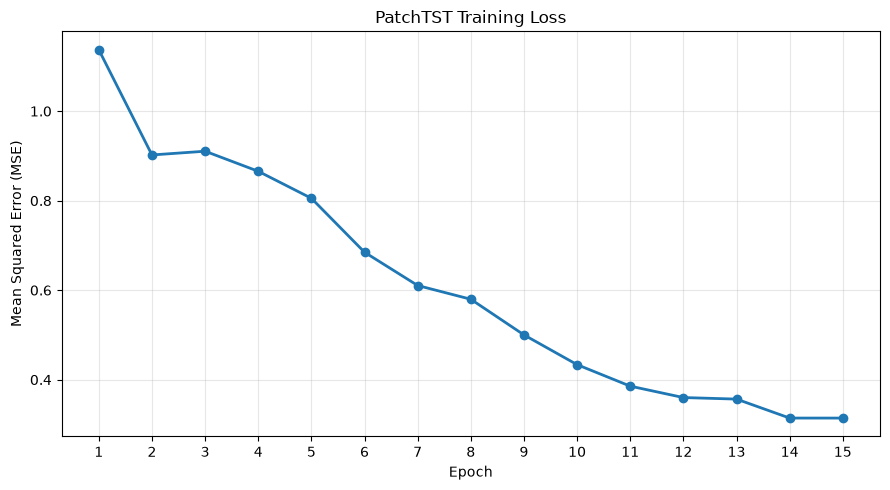

In [6]:
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("Results/PatchTST")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def plot_training_loss(losses):

    fig, ax = plt.subplots(figsize=(9, 5))

    ax.plot(
        range(1, len(losses) + 1),
        losses,
        marker="o",
        linewidth=2
    )

    ax.set_title("PatchTST Training Loss")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Mean Squared Error (MSE)")
    ax.set_xticks(range(1, len(losses) + 1))
    ax.grid(alpha=0.3)

    fig.tight_layout()

    fig.savefig(
        OUTPUT_DIR / "patchtst_training_loss.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


plot_training_loss(training_losses)

In [7]:
def predict(model, X):

    model.eval()

    with torch.no_grad():
        X_tensor = torch.tensor(
            X,
            dtype=torch.float32
        )

        predictions = model(X_tensor)

    return predictions.numpy()


# Store evaluation results
patchtst_results = []

for i in range(TRAIN_END, len(yraw)):

    # Previous 10 observations
    X_test = X0[i-WINDOW:i][None]

    # Predict scaled processing time
    pred_scaled = predict(patchtst, X_test)

    # Convert prediction to original units
    pred_original = sy0.inverse_transform(
        pred_scaled
    )[0, 0]

    patchtst_results.append({
        "idx": i,
        "phase": df.loc[i, "phase"],
        "actual": float(yraw[i]),
        "predicted": float(pred_original)
    })


# Create results DataFrame
patchtst_results_df = pd.DataFrame(patchtst_results)

print("Total PatchTST predictions:", len(patchtst_results_df))

display(patchtst_results_df.head())

Total PatchTST predictions: 595


,idx,phase,actual,predicted
0,400,stable,87.0,82.645363
1,401,stable,120.0,52.000664
2,402,stable,54.0,58.505554
3,403,stable,31.0,36.607136
4,404,stable,93.0,89.695946


In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

def calculate_metrics(group):

    actual = group["actual"]
    predicted = group["predicted"]

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    return pd.Series({
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2)
    })


# Calculate metrics for each operating phase
patchtst_metrics_df = (
    patchtst_results_df
    .groupby("phase", sort=False)
    .apply(calculate_metrics)
)

print("PatchTST Performance:")
display(patchtst_metrics_df)

PatchTST Performance:


,MAE,RMSE
phase,,
stable,27.63,34.13
drift,59.30,71.04
recovery,34.58,41.30


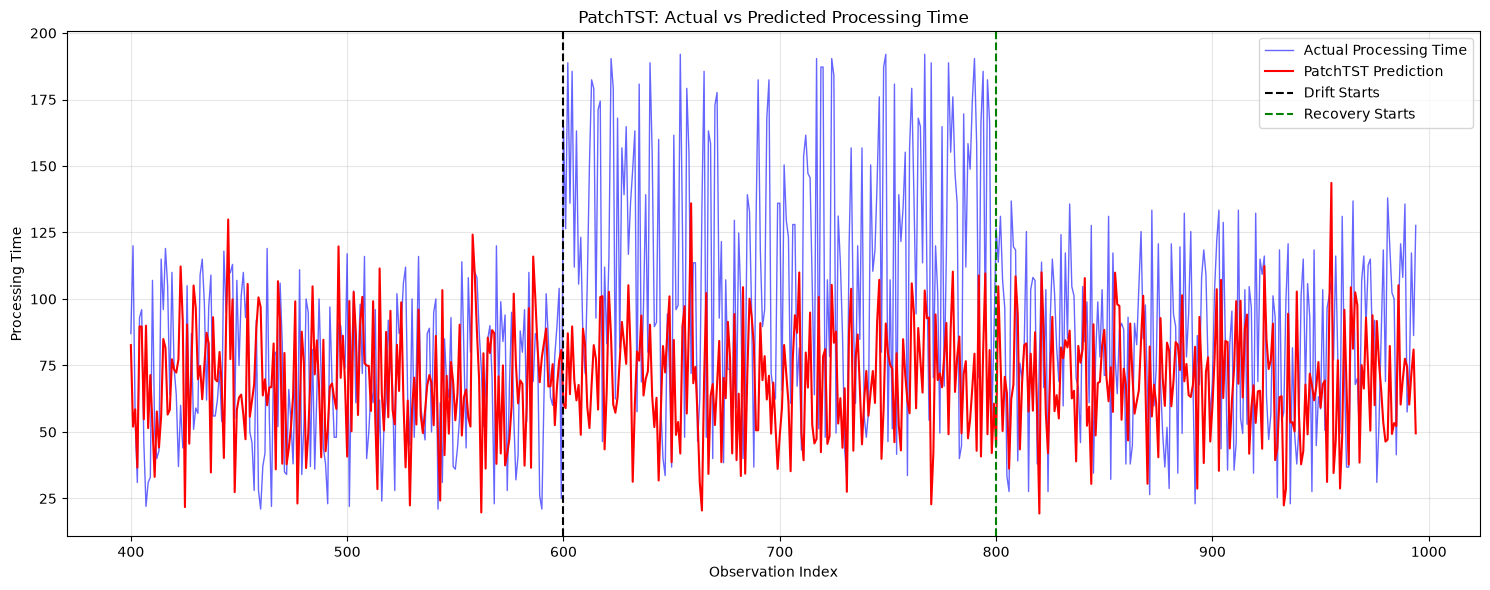

In [9]:
def plot_patchtst_predictions(results_df):

    fig, ax = plt.subplots(figsize=(15, 6))

    ax.plot(
        results_df["idx"],
        results_df["actual"],
        label="Actual Processing Time",
        color="blue",
        alpha=0.6,
        linewidth=1
    )

    ax.plot(
        results_df["idx"],
        results_df["predicted"],
        label="PatchTST Prediction",
        color="red",
        linewidth=1.5
    )

    ax.axvline(
        600, color="black",
        linestyle="--", label="Drift Starts"
    )

    ax.axvline(
        800, color="green",
        linestyle="--", label="Recovery Starts"
    )

    ax.set_title("PatchTST: Actual vs Predicted Processing Time")
    ax.set_xlabel("Observation Index")
    ax.set_ylabel("Processing Time")
    ax.legend()
    ax.grid(alpha=0.3)

    fig.tight_layout()

    fig.savefig(
        OUTPUT_DIR / "patchtst_actual_vs_predicted.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


plot_patchtst_predictions(patchtst_results_df)

In [10]:
# Save predictions
patchtst_results_df.to_csv(
    OUTPUT_DIR / "patchtst_predictions.csv",
    index=False
)

# Save metrics
patchtst_metrics_df.to_csv(
    OUTPUT_DIR / "patchtst_metrics.csv"
)

# Save trained model
torch.save(
    patchtst.state_dict(),
    OUTPUT_DIR / "patchtst_model.pth"
)

# Save scalers and model configuration
joblib.dump(
    {
        "sx": sx0,
        "sy": sy0,
        "features": FEATURES,
        "window": WINDOW,
        "patch_len": PATCH_LEN,
        "stride": STRIDE,
        "d_model": D_MODEL,
        "n_heads": N_HEADS,
        "n_layers": N_LAYERS,
        "dropout": DROPOUT
    },
    OUTPUT_DIR / "patchtst_config.joblib"
)

print("PatchTST results and model saved successfully!")

PatchTST results and model saved successfully!
